# Trazabilidad y calidad de la cartera SFC

## Resumen
Perfil descriptivo de cobertura y unicidad para datos agregados de calidad de cartera SFC; no certifica cumplimiento BCBS 239.

## Contexto y método
Los cambios de cobertura pueden reflejar cambios de reporte, entidades o fuente. Las pruebas describen un extracto público; no evalúan controles, integridad ni cumplimiento de una entidad.

## Datos y preparación
Ejecutar desde la raíz del repositorio o la carpeta del proyecto. Requiere Python, pandas, matplotlib y Jupyter.

Fuente: [calidad de cartera SFC](https://www.superfinanciera.gov.co/loader.php?idFile=1070109&lFuncion=descargar&lServicio=Tools2&lTipo=descargas), corte diciembre de 2023; transformación y manifiesto en `01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/`.

In [1]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True})

In [2]:
p=root/'03-financial-risk/01-credit-risk/credit-risk-products/observed-sfc-quality-proxy/results/sfc_icv_entity_modality_month.csv'
df=pd.read_csv(p,parse_dates=['period']); keys=['period','modality','entity_type_code','entity_code']
print('SHA-256 del extracto:',hashlib.sha256(p.read_bytes()).hexdigest())
print('Filas:',len(df),'| Duplicados de llave:',df.duplicated(keys).sum(),'| Período:',df.period.min().date(),df.period.max().date())
print('Nulos por columna:'); df.isna().sum().to_frame('nulos')

SHA-256 del extracto: 333144bae0eeae4713137a65a7126e7f39e2fe0bcf89337b366dda464e0c2fa8
Filas: 21050 | Duplicados de llave: 0 | Período: 2011-01-31 2023-12-31
Nulos por columna:


,nulos
period,0
modality,0
entity_type_code,0
entity_code,0
entity_name,0
fna_flag,0
icv_reported_ratio,0
icv_reported_pct,0


## Resultados

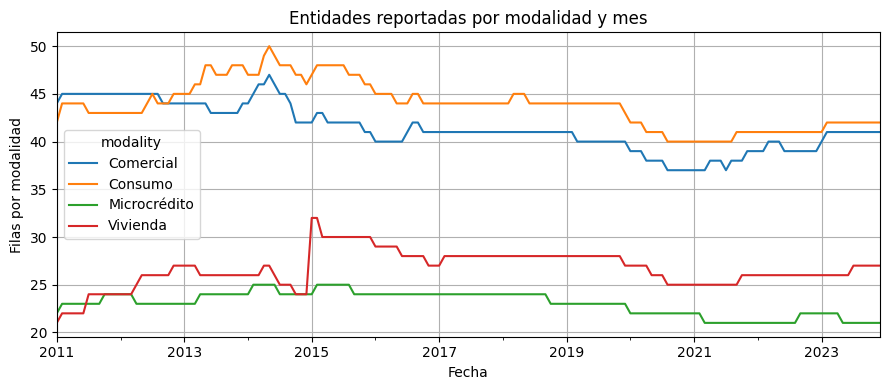

In [3]:
coverage=df.groupby(['period','modality']).size().unstack(); ax=coverage.plot(title='Entidades reportadas por modalidad y mes'); ax.set(xlabel='Fecha',ylabel='Filas por modalidad');plt.tight_layout();plt.show()

### Controles de calidad del extracto
La llave representa fecha, modalidad, tipo y código de entidad. Un dato faltante o fuera de rango requiere investigación; estas comprobaciones no prueban completitud contra los sistemas fuente.

In [4]:
print('Llaves incompletas:',int(df[keys].isna().any(axis=1).sum()))
print('Llaves duplicadas:',int(df.duplicated(keys,keep=False).sum()))
print('Razones fuera de [0, 1]:',int((~df.icv_reported_ratio.between(0,1) & df.icv_reported_ratio.notna()).sum()))
quality=df.groupby('modality').agg(filas=('period','size'),inicio=('period','min'),fin=('period','max'),entidades=('entity_code','nunique'))
quality

Llaves incompletas: 0
Llaves duplicadas: 0
Razones fuera de [0, 1]: 0


,filas,inicio,fin,entidades
modality,,,,
Comercial,6459,2011-01-31,2023-12-31,53
Consumo,6839,2011-01-31,2023-12-31,55
Microcrédito,3597,2011-01-31,2023-12-31,28
Vivienda,4155,2011-01-31,2023-12-31,34


## Variante: completitud temporal por modalidad
Se compara la presencia de al menos una fila de cada modalidad en cada mes del periodo observado. Es una cobertura de publicación del extracto: **no** mide completitud de entidades esperadas, exactitud ni el cumplimiento BCBS 239. [Basilea SRP36](https://www.bis.org/committees/bcbs/basel-framework/standard/srp/36/inforce/2019-12-15/published/2019-12-15) distingue exactitud, integridad y completitud; el linaje del extracto no sustituye un control institucional.

In [5]:
periodos=pd.date_range(df.period.min(),df.period.max(),freq='ME')
modalidades=sorted(df.modality.unique())
matriz=df.groupby(['period','modality']).size().unstack().reindex(index=periodos,columns=modalidades,fill_value=0).fillna(0)
resumen=pd.DataFrame({'meses_esperados':len(periodos),'meses_con_filas':(matriz>0).sum(),'meses_sin_filas':(matriz==0).sum()})
resumen['fraccion_meses_con_filas']=resumen.meses_con_filas/resumen.meses_esperados
resumen

,meses_esperados,meses_con_filas,meses_sin_filas,fraccion_meses_con_filas
modality,,,,
Comercial,156,156,0,1.0
Consumo,156,156,0,1.0
Microcrédito,156,156,0,1.0
Vivienda,156,156,0,1.0


## Alcance y decisión
Los cambios de cobertura pueden reflejar cambios de reporte, entidades o fuente. Las pruebas describen un extracto público; no evalúan controles, integridad ni cumplimiento de una entidad.

Fuente y metodología detalladas en el README y en el companion de origen. Este ejercicio no constituye validación independiente.